In [1]:
.libPaths("/mnt/pixstor/data/lsxgf/miniconda/envs/r-singlecell-r4.4-py3.10_geneEnrich/lib/R/library")

In [2]:

# Load necessary libraries
library(clusterProfiler)
library(org.Hs.eg.db)


Warning message:
“package ‘clusterProfiler’ was built under R version 4.4.2”


clusterProfiler v4.14.6 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

S Xu, E Hu, Y Cai, Z Xie, X Luo, L Zhan, W Tang, Q Wang, B Liu, R Wang,
W Xie, T Wu, L Xie, G Yu. Using clusterProfiler to characterize
multiomics data. Nature Protocols. 2024, 19(11):3292-3320


Attaching package: ‘clusterProfiler’


The following object is masked from ‘package:stats’:

    filter


Warning message:
“package ‘org.Hs.eg.db’ was built under R version 4.4.2”
Loading required package: AnnotationDbi

Warning message:
“package ‘AnnotationDbi’ was built under R version 4.4.2”
Loading required package: stats4

Loading required package: BiocGenerics

Warning message:
“package ‘BiocGenerics’ was built under R version 4.4.2”

Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base

## Figure 6b:

In [3]:
# combine GO and KEGG
save_dir = '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260416/'
save_dir = '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260709/'

# 0816
ensemble_mode = 'rankMin_study'
level = 'clonotype' # clonotype, cell

out_dir_root = "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814/"
save_dir = paste0(out_dir_root, ensemble_mode, '_', level, '/')

In [4]:
up_list = c('FGFBP2', 'GNLY', 'GZMB', 'HLA-DRA', 'IL7R', 'IRF4', 'LAIR2', 'TNFRSF18', 'XCL2', 'ZNF683', 'CD83', 'FASLG', 'GZMA')
down_list = c('CCL20', 'DNAJB1', 'FOS', 'FTL', 'HMOX1', 'HSPB1', 'LEF1', 'LGALS1', 'DUSP1', 'HSPA1A', 'HSPA1B', 'ANXA1', 'CD69', 'DDIT3', 'CCR7', 'KLRG1', 'TIMP1')

up_list = c(
'GZMB','CCL4','KLRD1','CCL3','IL7R','GZMK','CCL4L2','KLRC1','DUSP2','GZMA','TRDC','ZNF683','CD83','GADD45B','GZMH','GNLY','FASLG','FGFBP2','TNF','TNFRSF18','HLA-DRA','IRF4','TRGV5','TRBV6-5','TRBV5-6','RGS1','TRDV1','TRBV18')
down_list = c(
    'LGALS1','HSPA1A','HSPA1B','SAT1','ANXA1','FOS','TIMP1','KLRG1','HSPB1','MYC','TUBB','DUSP1','TUBA1B','CD69','STMN1','FTL','DNAJB1','LEF1','MAL','CCR7'
)

# 0816
gene_1_fiPath = paste0(save_dir,
"GRN_gene_embedding_Chiffelle_genes_celltype_1.csv")
up_list = read.csv(gene_1_fiPath)$genes_celltype_1

gene_0_fiPath = paste0(save_dir,
"GRN_gene_embedding_Chiffelle_genes_celltype_0.csv")
down_list = read.csv(gene_0_fiPath)$genes_celltype_0


convert_gene <- function(genes) {
    bitr(genes,
         fromType = "SYMBOL",
         toType = "ENTREZID",
         OrgDb = org.Hs.eg.db)
}

g1 <- convert_gene(up_list)
g2 <- convert_gene(down_list)

up_list_ <- g1$ENTREZID
down_list_ <- g2$ENTREZID


gene_clusters <- list(
    Reactive = up_list_,
    Non_reactive = down_list_
)



'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns



In [5]:
down_list_

[1] "3956"   "3303"   "3162"   "3304"   "3925"   "51176"  "6303"   "10219" 
 [9] "3315"   "4609"   "301"    "2353"   "1843"   "969"    "7076"   "10376" 
[17] "203068" "3337"   "2512"   "4118"   "1236"

In [6]:
length(down_list) == length(down_list_)

[1] TRUE

In [7]:
ego_compare <- compareCluster(
    geneCluster = gene_clusters,
    fun = "enrichGO",
    OrgDb = org.Hs.eg.db,
    ont = "ALL"
)

kegg_compare <- compareCluster(
    geneCluster = gene_clusters,
    fun = "enrichKEGG",
    organism = "hsa"
)


In [8]:
df_go <- as.data.frame(ego_compare)
df_kegg <- as.data.frame(kegg_compare)

df_go$Category <- "GO"
df_kegg$Category <- "KEGG"

common_cols <- c("Cluster", "Description", "p.adjust", "GeneRatio", "Count", "Category")

df_go <- df_go[, common_cols]
df_kegg <- df_kegg[, common_cols]

In [9]:
as.data.frame(kegg_compare) %>% arrange(p.adjust) %>% head(15)

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,geneID,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>
1,Reactive,Human Diseases,Immune disease,hsa05332,Graft-versus-host disease,7/17,45/9422,0.15555556,86.21438,24.360194,6.527780e-13,6.984725e-11,4.122808e-11,3002/3824/3821/3458/356/3122/7124,7
2,Reactive,Human Diseases,Immune disease,hsa05330,Allograft rejection,5/17,39/9422,0.12820513,71.05581,18.637993,5.559197e-09,2.974171e-07,1.755536e-07,3002/3458/356/3122/7124,5
3,Reactive,Human Diseases,Endocrine and metabolic disease,hsa04940,Type I diabetes mellitus,5/17,44/9422,0.11363636,62.98128,17.519647,1.043023e-08,3.720114e-07,2.195837e-07,3002/3458/356/3122/7124,5
4,Reactive,Environmental Information Processing,Signaling molecules and interaction,hsa04060,Cytokine-cytokine receptor interaction,8/17,298/9422,0.02684564,14.87880,10.350491,1.730224e-08,4.628349e-07,2.731932e-07,6351/6348/6846/3458/9560/356/8784/7124,8
5,Reactive,Organismal Systems,Immune system,hsa04650,Natural killer cell mediated cytotoxicity,6/17,133/9422,0.04511278,25.00310,11.852287,7.697418e-08,1.647247e-06,9.723054e-07,3002/3824/3821/3458/356/7124,6
6,Reactive,Organismal Systems,Immune system,hsa04612,Antigen processing and presentation,5/17,82/9422,0.06097561,33.79484,12.680387,2.516487e-07,4.487736e-06,2.648934e-06,3824/3821/3458/3122/7124,5
7,Reactive,Environmental Information Processing,Signaling molecules and interaction,hsa04061,Viral protein interaction with cytokine and cytokine receptor,5/17,100/9422,0.05000000,27.71176,11.416726,6.811454e-07,1.041179e-05,6.145673e-06,6351/6348/6846/9560/7124,5
8,Non_reactive,Environmental Information Processing,Signal transduction,hsa04010,MAPK signaling pathway,7/16,301/9422,0.02325581,13.69477,9.231936,2.829508e-07,3.055869e-05,2.233822e-05,3303/3304/3925/3315/4609/2353/1843,7
9,Reactive,Human Diseases,Immune disease,hsa05323,Rheumatoid arthritis,4/17,95/9422,0.04210526,23.33622,9.302381,2.087638e-05,2.792216e-04,1.648136e-04,6348/3458/3122/7124,4


In [10]:
library(dplyr)

df_go_top <- df_go %>% arrange(p.adjust) %>% head(10)
df_kegg_top <- df_kegg %>% arrange(p.adjust) %>% head(8)

df_all <- rbind(df_go_top, df_kegg_top)

Warning message:
“package ‘dplyr’ was built under R version 4.4.2”

Attaching package: ‘dplyr’


The following object is masked from ‘package:AnnotationDbi’:

    select


The following objects are masked from ‘package:IRanges’:

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from ‘package:S4Vectors’:

    first, intersect, rename, setdiff, setequal, union


The following object is masked from ‘package:Biobase’:

    combine


The following objects are masked from ‘package:BiocGenerics’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [11]:
df_kegg_top

,Cluster,Description,p.adjust,GeneRatio,Count,Category
,<fct>,<chr>,<dbl>,<chr>,<int>,<chr>
1,Reactive,Graft-versus-host disease,6.984725e-11,7/17,7,KEGG
2,Reactive,Allograft rejection,2.974171e-07,5/17,5,KEGG
3,Reactive,Type I diabetes mellitus,3.720114e-07,5/17,5,KEGG
4,Reactive,Cytokine-cytokine receptor interaction,4.628349e-07,8/17,8,KEGG
5,Reactive,Natural killer cell mediated cytotoxicity,1.647247e-06,6/17,6,KEGG
6,Reactive,Antigen processing and presentation,4.487736e-06,5/17,5,KEGG
7,Reactive,Viral protein interaction with cytokine and cytokine receptor,1.041179e-05,5/17,5,KEGG
8,Non_reactive,MAPK signaling pathway,3.055869e-05,7/16,7,KEGG


In [12]:
df_go %>% arrange(p.adjust) %>% head(15)

,Cluster,Description,p.adjust,GeneRatio,Count,Category
,<fct>,<chr>,<dbl>,<chr>,<int>,<chr>
1,Reactive,cell killing,1.295348e-06,8/25,8,GO
2,Non_reactive,regulation of hemopoiesis,1.240077e-05,8/21,8,GO
3,Reactive,cytokine activity,1.315375e-05,6/22,6,GO
4,Reactive,cytokine receptor binding,1.602668e-05,6/22,6,GO
5,Reactive,external side of plasma membrane,1.627745e-05,7/25,7,GO
6,Reactive,cytolytic granule,1.627745e-05,3/25,3,GO
7,Reactive,regulation of alpha-beta T cell differentiation,3.401476e-05,5/25,5,GO
8,Reactive,humoral immune response,4.208385e-05,7/25,7,GO
9,Non_reactive,response to heat,5.384324e-05,5/21,5,GO


In [13]:
df_all

Cluster,Description,p.adjust,GeneRatio,Count,Category
<fct>,<chr>,<dbl>,<chr>,<int>,<chr>
Reactive,cell killing,1.295348e-06,8/25,8,GO
Non_reactive,regulation of hemopoiesis,1.240077e-05,8/21,8,GO
Reactive,cytokine activity,1.315375e-05,6/22,6,GO
Reactive,cytokine receptor binding,1.602668e-05,6/22,6,GO
Reactive,external side of plasma membrane,1.627745e-05,7/25,7,GO
Reactive,cytolytic granule,1.627745e-05,3/25,3,GO
Reactive,regulation of alpha-beta T cell differentiation,3.401476e-05,5/25,5,GO
Reactive,humoral immune response,4.208385e-05,7/25,7,GO
Non_reactive,response to heat,5.384324e-05,5/21,5,GO


In [14]:
df_all <- df_all %>%
  arrange(Cluster, desc(GeneRatio), desc(p.adjust))

In [15]:
df_all

Cluster,Description,p.adjust,GeneRatio,Count,Category
<fct>,<chr>,<dbl>,<chr>,<int>,<chr>
Reactive,cell killing,1.295348e-06,8/25,8,GO
Reactive,Cytokine-cytokine receptor interaction,4.628349e-07,8/17,8,KEGG
Reactive,regulation of leukocyte differentiation,5.566796e-05,7/25,7,GO
Reactive,humoral immune response,4.208385e-05,7/25,7,GO
Reactive,external side of plasma membrane,1.627745e-05,7/25,7,GO
Reactive,Graft-versus-host disease,6.984725e-11,7/17,7,KEGG
Reactive,cytokine receptor binding,1.602668e-05,6/22,6,GO
Reactive,cytokine activity,1.315375e-05,6/22,6,GO
Reactive,Natural killer cell mediated cytotoxicity,1.647247e-06,6/17,6,KEGG


In [16]:
df_all$Description

[1] "cell killing"                                                 
 [2] "Cytokine-cytokine receptor interaction"                       
 [3] "regulation of leukocyte differentiation"                      
 [4] "humoral immune response"                                      
 [5] "external side of plasma membrane"                             
 [6] "Graft-versus-host disease"                                    
 [7] "cytokine receptor binding"                                    
 [8] "cytokine activity"                                            
 [9] "Natural killer cell mediated cytotoxicity"                    
[10] "regulation of alpha-beta T cell differentiation"              
[11] "Viral protein interaction with cytokine and cytokine receptor"
[12] "Antigen processing and presentation"                          
[13] "Type I diabetes mellitus"                                     
[14] "Allograft rejection"                                          
[15] "cytolytic granule"                                            
[16] "regulation of hemopoiesis"                                    
[17] "MAPK signaling pathway"                                       
[18] "response to heat"

Warning message:
“package ‘ggplot2’ was built under R version 4.4.2”


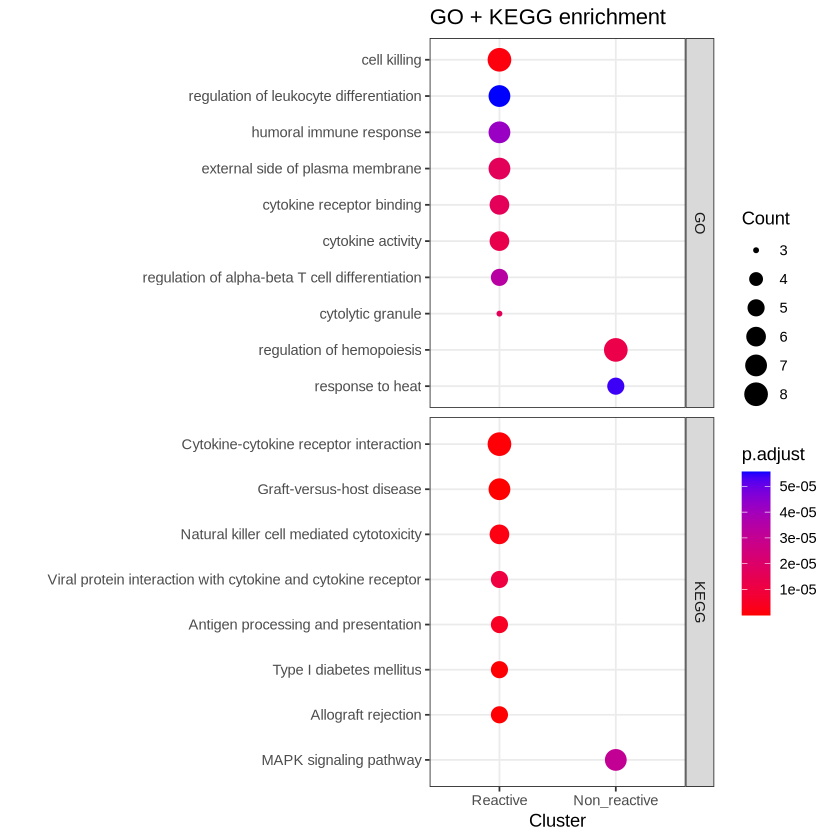

In [17]:
df_all <- df_all[!duplicated(df_all$Description), ]
df_all$Description <- factor(df_all$Description, levels = rev(df_all$Description))

library(ggplot2)

ggplot(df_all, aes(x = Cluster, y = Description)) +
    geom_point(aes(size = Count, color = p.adjust)) +
    facet_grid(Category ~ ., scales = "free_y") +
    scale_color_continuous(low = "red", high = "blue") +
    theme_bw() +
    labs(title = "GO + KEGG enrichment", y = "", x = "Cluster")

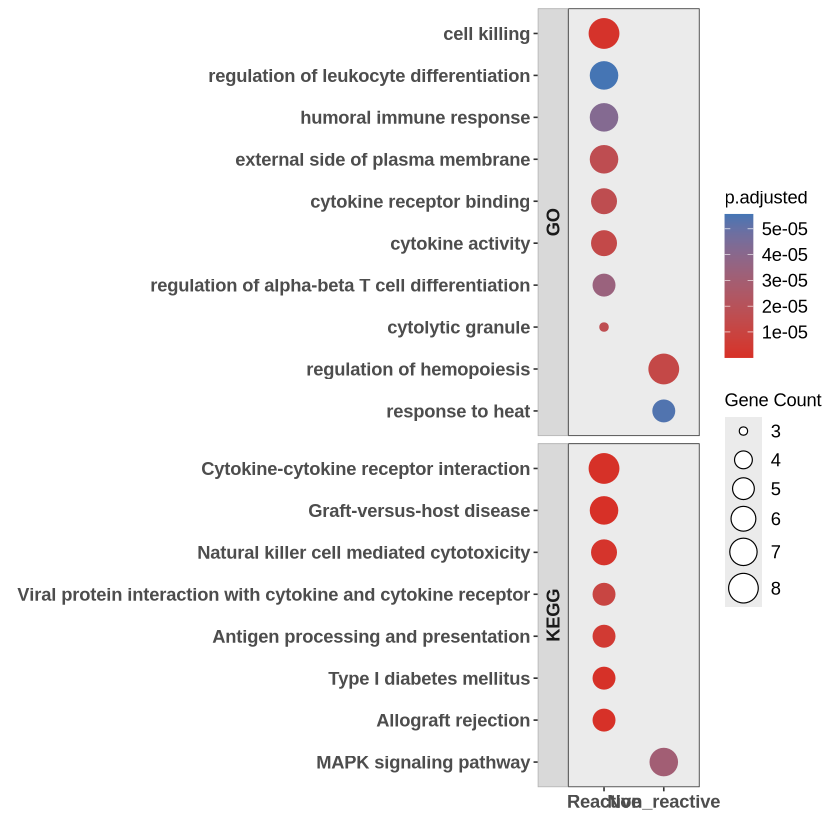

In [19]:
library(ggplot2)
library(dplyr)

# ensure ordering already done

p <- ggplot(df_all, aes(x = Cluster, y = Description)) +
  geom_point(aes(size = Count, color = p.adjust)) +
  
  # facet on LEFT side
  facet_grid(Category ~ ., scales = "free_y", space = "free_y", switch = "y") +
  
  # red → blue color (like paper)
  scale_color_gradient(
    low = "#d73027",   # red (significant)
    high = "#4575b4",  # blue (less significant)
    name = "p.adjusted"
  ) +
  
  # size scale like paper
  scale_size(range = c(2, 8), name = "Gene Count") +
  
  theme_bw(base_size = 10) +
  
  theme(
    # Y labels (smaller, tighter)
    axis.text.y = element_text(size = 11, face = 'bold'),
    axis.text.x = element_text(size = 11, face = 'bold'),
    
    # remove gridlines
    panel.grid = element_blank(),
    
    # facet strips on LEFT
    #strip.placement = "left",
    strip.text.y.left = element_text(angle = 90, size = 11, face = "bold"),
    
    # grey facet background
    strip.background = element_rect(fill = "grey85", color = "grey70"),
    
    # panel background light grey
    panel.background = element_rect(fill = "grey92"),
    
    # spacing tighter
    panel.spacing = unit(0.3, "lines"),
    
    # legend
    legend.position = "right",
    legend.title = element_text(size = 11),
    legend.text = element_text(size = 11)
  ) +

   guides(
      size = guide_legend(
        override.aes = list(
          fill = "white",
          color = "black",
          shape = 21,
          stroke = 0.5
        )
      )
    ) +
  
  labs(
    x = "",
    y = NULL
  )

print(p)

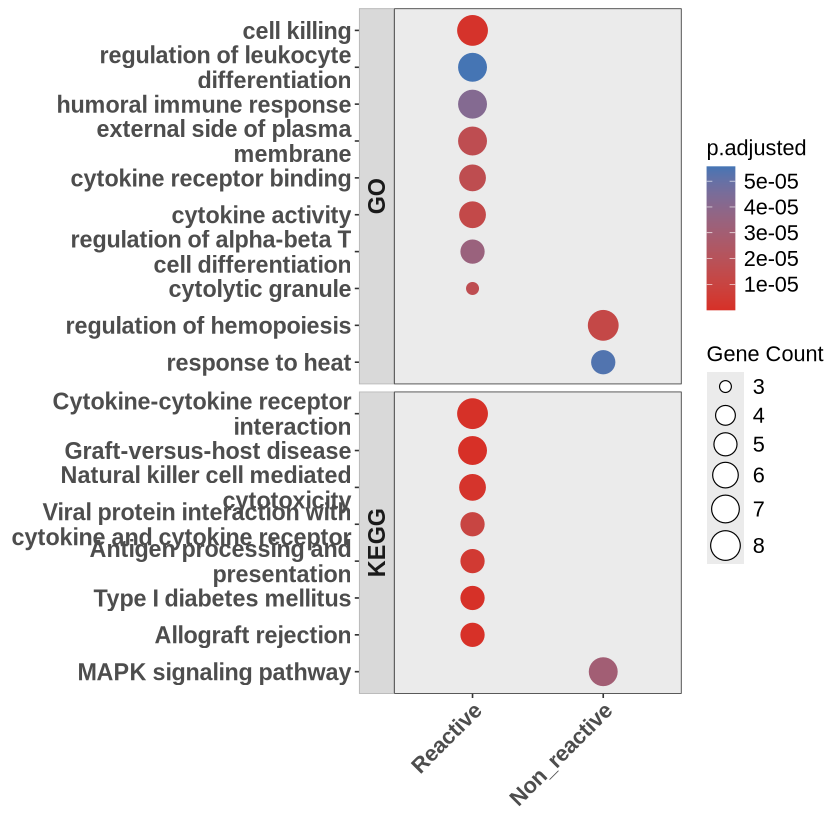

In [31]:
library(ggplot2)
library(dplyr)
library(stringr)   # for str_wrap

p <- ggplot(df_all, aes(x = Cluster, y = Description)) +
  geom_point(aes(size = Count, color = p.adjust)) +
  
  facet_grid(Category ~ ., scales = "free_y", space = "free_y", switch = "y") +
  
  scale_color_gradient(
    low = "#d73027",
    high = "#4575b4",
    name = "p.adjusted"
  ) +
  
  scale_size(range = c(3, 8), name = "Gene Count") +
  
  # wrap long y-axis labels onto 2 (or more) lines at ~28 characters
  scale_y_discrete(labels = function(x) str_wrap(x, width = 30)) +
  
  theme_bw(base_size = 10) +
  
  theme(
    axis.text.y = element_text(size = 14, face = 'bold'),
    
    # rotate x-axis labels
    axis.text.x = element_text(size = 13, face = 'bold', angle = 45, hjust = 1, vjust = 1),
    
    panel.grid = element_blank(),
    
    strip.text.y.left = element_text(angle = 90, size = 14, face = "bold"),
    strip.background = element_rect(fill = "grey85", color = "grey70"),
    panel.background = element_rect(fill = "grey92"),
    panel.spacing = unit(0.3, "lines"),
    
    legend.position = "right",
    legend.title = element_text(size = 13),
    legend.text = element_text(size = 13)
  ) +
  guides(
    size = guide_legend(
      override.aes = list(
        fill = "white",
        color = "black",
        shape = 21,
        stroke = 0.5
      )
    )
  ) +
  
  labs(
    x = "",
    y = NULL
  )
print(p)

In [32]:
ggsave(paste0(save_dir,"geneEmb_gene_GO_KEGG_dotplot.png"), p, width = 6, height = 9, create.dir = TRUE, dpi = 300)

In [22]:
save_dir

[1] "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260709/"